# Audit summary numbers

This notebook recomputes the summary numbers and the defect chart of the benchmark audit. It reads `audit_log.csv` (one row per task and check), `results/static_scan.csv` (the no-op scan of all 50 airline tasks) and `sample.json` (the 20 sampled task ids and the pinned benchmark commit). All logic lives in `make_summary.py`; this notebook only calls it. A task counts as defective when it has at least one confirmed defect of severity high or medium. Every share carries a 95% Wilson interval.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
import make_summary

make_summary.selftest()
md = make_summary.run(ROOT)

selftest passed


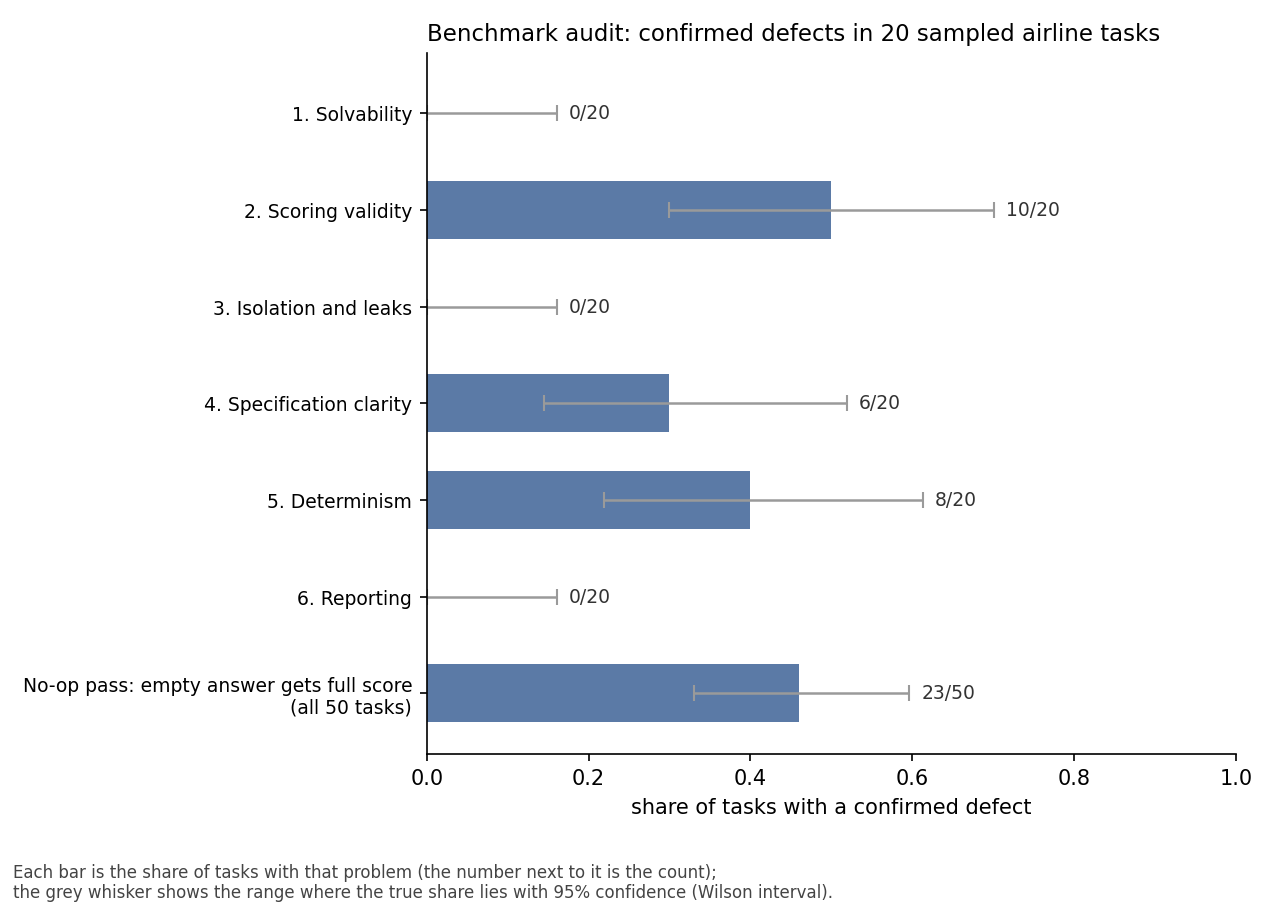

In [2]:
from IPython.display import Image, display

display(Image(filename=str(ROOT / 'fig_defects.png')))

In [3]:
print((ROOT / 'summary_numbers.md').read_text(encoding='utf-8'))

# Summary numbers

bench_commit: `989d3285ae669e49503324bdb9981bf14fccedeb`

Intervals: 95% Wilson.

Table 1. Headline shares

| quantity | share |
|---|---|
| defective tasks, sampled tasks | 18/20 = 0.900 [0.699, 0.972] |
| defective tasks, sampled tasks, static and probe checks only (method ≠ agent_run) | 13/20 = 0.650 [0.433, 0.819] |
| defective tasks, sampled tasks, agent_run checks only (1e, 4f, 5c, 5d, 5e, 5f) | 9/20 = 0.450 [0.258, 0.658] |
| defective tasks, sampled tasks, agent_run checks excluding 5d (user-simulator deviations) | 5/20 = 0.250 [0.112, 0.469] |
| tasks whose only confirmed defects come from agent_run checks (new versus the static phase) | 5/20 = 0.250 [0.112, 0.469] |
| defective tasks, sampled tasks, excluding the documented no-op class (checks 2a, 2b) | 16/20 = 0.800 [0.584, 0.919] |
| defective tasks, sampled tasks, excluding every defect that derives from the no-op design (checks 2a, 2b, and 2k rows on tasks with noop_pass = 1 in results/static_scan.csv) 